# 无监督学习

## K-Means


### 1.基本思想：
将一堆数据分为k个簇，以每个簇的均值作为各个簇的中心
### 2.解决的问题：
将n个样本分为k个簇后，使得每个样本到它所属的中心的距离的平方和最小
这个距离平方和叫做 SSE（Sum of Squared Errors，误差平方和），也叫 惯性（inertia），公式如下：
$$
SSE = \sum_{i=1}^{K} \sum_{x \in C_i} \| x - \mu_i \|^2
$$

$C_i$：第 $i$ 个簇中的所有样本；
$\mu_i$：第 $i$ 个簇的中心（均值向量）；
$\| x - \mu_i \|^2$：样本 $x$ 到它所在簇中心 $\mu_i$ 的欧氏距离的平方。
### 3.目标：不断迭代调整中心，使得这个SSE越来越小
### 4.算法步骤：
(1)随机选择K个中心点

(2)分配样本到每个簇中

(3)重新计算各个簇的均值作为新的中心点

(4)迭代重复2，3步，直到K个中心点不再明显移动

上述步骤在sklearn中已经被集成封装，在准备好标准化后的数据X_scaled后，直接调用下述语句

In [ ]:
from sklearn.cluster import  KMeans
km=KMeans(n_clusters=K,random_state=42)#准备好的km模型
km.fit(X_scaled)#训练模型，X_scaled是标准化后的数据

##### 上文中提到了标准化的数据X_scaled,下面讲述该预处理步骤
原因：K-Means中是根据样本之间的距离来分配簇，距离公式为
$
d(\mathbf{x}_i, \mathbf{x}_j) = \sqrt{\sum_{f=1}^{m} (x_{if} - x_{jf})^2}
$
距离对特征尺度敏感，如果样本中存在数值较大的数，会导致其对距离的贡献显著超过其他样本，则多分类问题中一些影响因素会被忽略，这并不利于聚类结果，所以需要加以标准化，使其范围大多处于[0,1]之间。

常用的标准化方法是 Z-score 标准化（StandardScaler）：
$$
x' = \frac{x - \mu}{\sigma}
$$
其中 $\mu$ 为特征均值，$\sigma$ 为标准差。

可使用sklearn中的StandardScaler进行标准化
示例代码如下：

In [ ]:
#先对原始数据X进行标准化
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()#创建标准化器
X_scaled=scaler.fit_transform(X)#对原始数据进行标准化

### 5.影响K-means聚类的因素：K的选择
K-means的基本步骤均以在sklearn中被继承，需要我们前置准备的就只有准备标准化后的数据和挑选K
#### 挑选K的算法：
##### (1)肘部法则(Elbow Method)

##### (2)轮廓系数(Silhouette Score)

基本思想：对于合适的K，会有以下特征：单个样本与同簇内其他样本的平均距离很小（凝聚度），与其他簇内的样本平均距离（分离度）很大，由此得到单个样本的轮廓系数，用以下公式表示：

$$
s(i) = \frac{b(i) - a(i)}{\max\big(a(i), b(i)\big)}
$$

$$(a(i)为凝聚度，b(i)为分离度)$$


$$
a(i) = \frac{1}{|C_I| - 1} \sum_{j \in C_I, j \ne i} d(i, j)
$$

其中 $C_I$ 是样本 $i$ 所属的簇，$d(i,j)$ 是两个样本之间的距离（通常用欧氏距离）。

$$
b(i) = \min_{J \ne I} \frac{1}{|C_J|} \sum_{j \in C_J} d(i, j)
$$

整体轮廓系数将所有样本的 $s(i)$ 求平均，就得到整个聚类结果的轮廓系数：
$$S = \frac{1}{n} \sum_{i=1}^{n} s(i)
$$
取值范围仍在 [-1, 1] 之间，且Score越靠近1，K值越好

sklearn中也集成了此功能

演示代码如下：

In [ ]:
#对K的轮廓系数(2到10)进行计算比较
from sklearn.metrics import silhouette_score
silhouette_score=[]
k_range=range(2,11)
for k in k_range:
    km=KMeans(n_cluster=k,random_state=42)
    labels=km.fit_predict(X_scaled)#进行训练后各样本的聚类标签
    score=silhouette_score(X_scaled,labels)
    silhouette_score.append(score)


*e.g.1 mvn分布点集(两个簇较为分立)*

d:\Miniconda3\envs\ML\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


Silhouette Score (K=2): 0.785


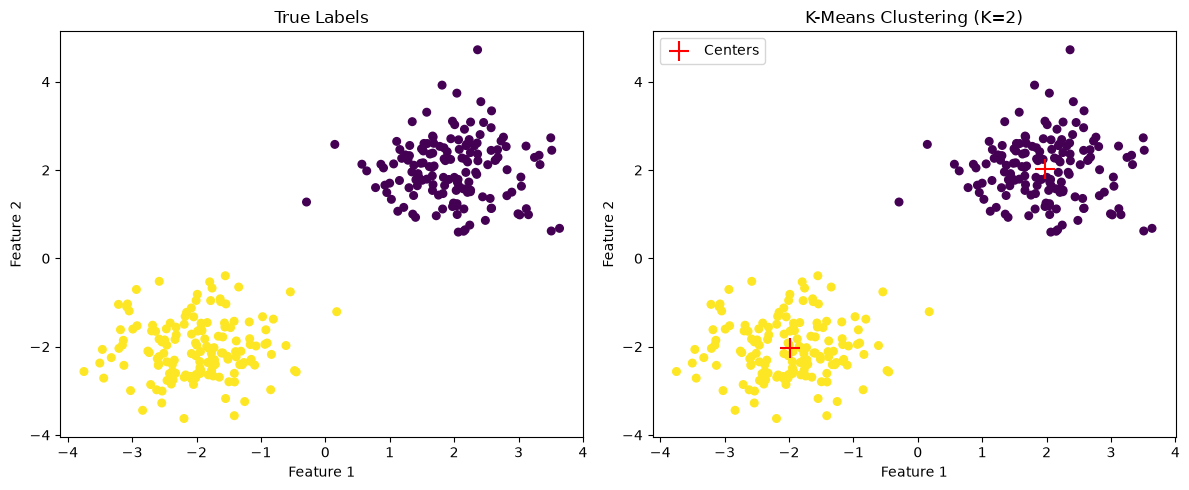

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# 设置随机种子，保证结果可复现
np.random.seed(42)

# 簇1的参数：均值 [2, 2]，协方差矩阵（较小散布）
mean1 = [2, 2]
cov1 = [[0.5, 0], [0, 0.5]]
data1 = np.random.multivariate_normal(mean1, cov1, size=150)

# 簇2的参数：均值 [-2, -2]，协方差矩阵（较小散布）
mean2 = [-2, -2]
cov2 = [[0.5, 0], [0, 0.5]]
data2 = np.random.multivariate_normal(mean2, cov2, size=150)

# 合并数据
X = np.vstack([data1, data2])
# 真实标签（仅用于对比，实际聚类时不用）
true_labels = np.array([0]*150 + [1]*150)

# 标准化（K-Means 对尺度敏感）
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 训练 K-Means（簇数设为2）
km = KMeans(n_clusters=2, random_state=42)
km.fit(X_scaled)
predicted_labels = km.labels_

# 计算轮廓系数
sil_score = silhouette_score(X_scaled, predicted_labels)
print(f"Silhouette Score (K=2): {sil_score:.3f}")

# 反变换聚类中心到原始尺度
centers_original = scaler.inverse_transform(km.cluster_centers_)

# 绘图：左边显示真实标签，右边显示 K-Means 预测结果
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 真实标签
axes[0].scatter(X[:, 0], X[:, 1], c=true_labels, cmap='viridis', s=30)
axes[0].set_title('True Labels')
axes[0].set_xlabel('Feature 1')
axes[0].set_ylabel('Feature 2')

# 预测标签
axes[1].scatter(X[:, 0], X[:, 1], c=predicted_labels, cmap='viridis', s=30)
axes[1].scatter(centers_original[:, 0], centers_original[:, 1], 
                marker='+', s=200, c='red', label='Centers')
axes[1].set_title('K-Means Clustering (K=2)')
axes[1].set_xlabel('Feature 1')
axes[1].set_ylabel('Feature 2')
axes[1].legend()

plt.tight_layout()
plt.show()

*e.g.2 mvn分布（数据有重叠，显示K-Means的劣势）*

d:\Miniconda3\envs\ML\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


轮廓系数 (K=2): 0.354
调整兰德指数 (与真实标签对比): 0.301


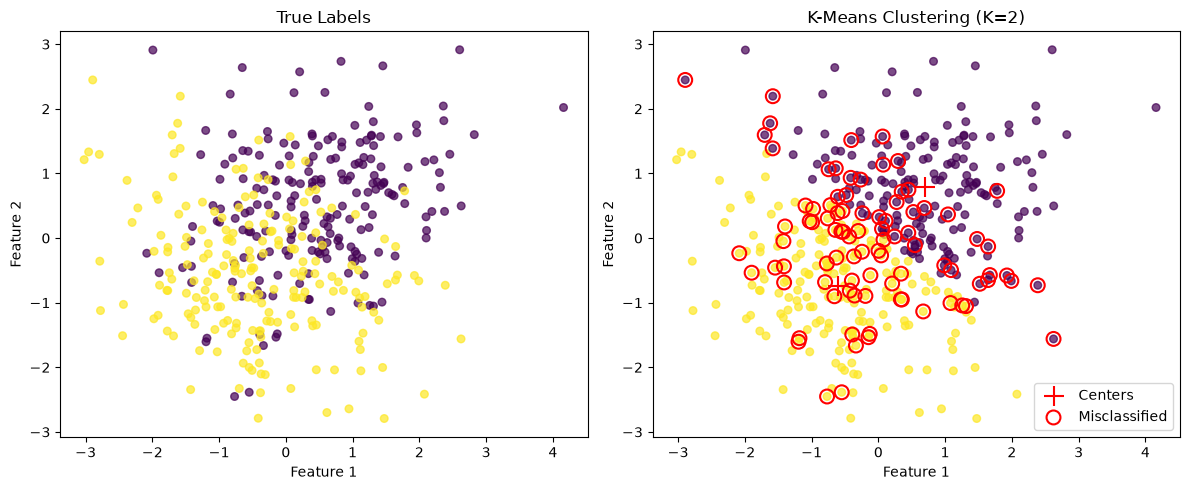

d:\Miniconda3\envs\ML\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
d:\Miniconda3\envs\ML\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
d:\Miniconda3\envs\ML\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
d:\Miniconda3\envs\ML\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, 

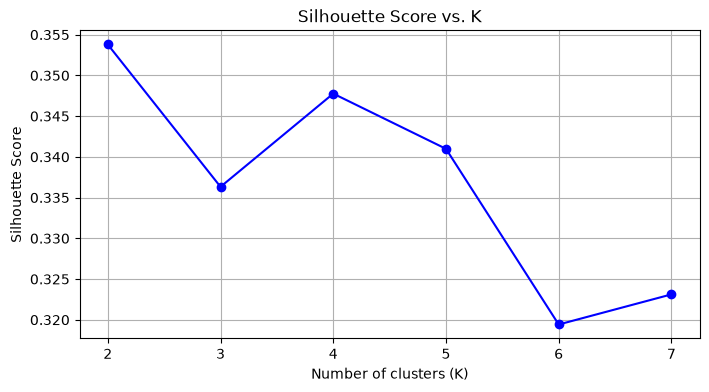

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score

# 设置随机种子
np.random.seed(42)

# 簇1参数：均值 [0.5, 0.5]，协方差较大，产生重叠
mean1 = [0.5, 0.5]
cov1 = [[1.2, 0.3], [0.3, 1.0]]   # 非对角协方差使分布呈椭圆并倾斜
data1 = np.random.multivariate_normal(mean1, cov1, size=200)

# 簇2参数：均值 [-0.5, -0.5]，协方差类似
mean2 = [-0.5, -0.5]
cov2 = [[1.2, -0.3], [-0.3, 1.0]]
data2 = np.random.multivariate_normal(mean2, cov2, size=200)

# 合并数据
X = np.vstack([data1, data2])
true_labels = np.array([0]*200 + [1]*200)

# 标准化（K-Means 默认使用欧氏距离，标准化可均衡各特征尺度）
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 训练 K-Means，K=2
km = KMeans(n_clusters=2, random_state=42)
km.fit(X_scaled)
pred_labels = km.labels_

# 评估
sil = silhouette_score(X_scaled, pred_labels)
ari = adjusted_rand_score(true_labels, pred_labels)
print(f"轮廓系数 (K=2): {sil:.3f}")
print(f"调整兰德指数 (与真实标签对比): {ari:.3f}")

# 将聚类中心反变换到原始尺度
centers_orig = scaler.inverse_transform(km.cluster_centers_)

# 可视化：左图真实标签，右图预测标签，标记误分类点
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 左图：真实标签
axes[0].scatter(X[:,0], X[:,1], c=true_labels, cmap='viridis', s=30, alpha=0.7)
axes[0].set_title('True Labels')
axes[0].set_xlabel('Feature 1')
axes[0].set_ylabel('Feature 2')

# 右图：预测标签
axes[1].scatter(X[:,0], X[:,1], c=pred_labels, cmap='viridis', s=30, alpha=0.7)
axes[1].scatter(centers_orig[:,0], centers_orig[:,1], marker='+', s=200, c='red', label='Centers')
axes[1].set_title('K-Means Clustering (K=2)')
axes[1].set_xlabel('Feature 1')
axes[1].set_ylabel('Feature 2')
axes[1].legend()

# 标记误分类点（在右图中用红色圆圈标出）
misclassified = true_labels != pred_labels
axes[1].scatter(X[misclassified,0], X[misclassified,1], 
                facecolors='none', edgecolors='red', s=100, linewidths=1.5, label='Misclassified')
axes[1].legend()

plt.tight_layout()
plt.show()

# 额外：观察不同K值下的轮廓系数
K_range = range(2, 8)
sil_scores = []
for k in K_range:
    km_test = KMeans(n_clusters=k, random_state=42)
    km_test.fit(X_scaled)
    sil_scores.append(silhouette_score(X_scaled, km_test.labels_))

plt.figure(figsize=(8, 4))
plt.plot(K_range, sil_scores, 'bo-')
plt.xlabel('Number of clusters (K)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score vs. K')
plt.grid(True)
plt.show()

# 监督学习

## I.Linear Regression

### 1.解决的问题：回归问题（用已知数据去预测）
### 2.基本思想：假设目标变量y与特征变量之间是线性关系，即
$$
y = w_1 x_1 + w_2 x_2 + \dots + w_m x_m + b
$$

(w：权重系数;b:截距)

该算法实现过程中的目标就是寻找到合适的w和b，但应该如何去评判“合适”？

### 3.the target of Linear Regression---Loss Function:

常用均方误差(Mean Squared Error,MSE)作为损失函数:
$$
\text{MSE} = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2
$$
其中 $n$ 是样本数，$\hat{y}_i = w^T x_i + b$ 是模型预测值。
因此线性回归的目标就是最小化MSE。
### 4.模型求解：
(i)梯度下降

(ii)正规方程(解析解)：通过最小二乘法求得最优参数的闭式解：
$$
\mathbf{w} = (\mathbf{X}^T \mathbf{X})^{-1} \mathbf{X}^T \mathbf{y}
$$
sklearn中的LinearRegressioin使用基于scipy的最小二乘法求解，本质为解析法，对于中小规模数据求解很高效。

### 4.模型评估指标
| 指标 | 公式 | 含义 |
|------|------|------|
| **R²** | $R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$| 决定系数，衡量模型解释了多少目标变量的方差，取值范围 (-\infty, 1]，越接近 1 越好 |
| **MSE** | $\frac{1}{n} \sum (y_i - \hat{y}_i)^2$ | 均方误差，越小越好 |
| **RMSE** | $\sqrt{\text{MSE}}$| 均方根误差，与目标变量同单位，越小越好 |
| **MAE** | $\frac{1}{n} \sum \lvert y_i - \hat{y}_i \rvert$| 平均绝对误差，对异常值不那么敏感 |

### 5.线性回归基本步骤(by sklearn)
划分数据(train set,test set)->模型实例化，训练->预测->评价

示例代码如下：

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score,mean_squared_error
from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np
bikes=pd.read_csv('e2.2_bikeshare.csv',index_col='datetime',parse_dates=True)

x=bikes[['temp']]
y=bikes['count']

x_train,x_test,y_train,y_test=train_test_split(
    x,y,test_size=0.2,random_state=42
)

lr=LinearRegression()
lr.fit(x_train,y_train)

y_pred=lr.predict(x_test)
print(f"r2_score: {r2_score(y_test,y_pred):.3f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test,y_pred)):.3f}")

r2_score: 0.169
RMSE: 165.590


## II Logistic Regression

### 1.解决的问题：
Linear Regression 主要用于预测连续数值，且对异常值敏感。

目标变量为类别时（离散），需要用到Logistic Regression
输出从预测值变为预测落在某个分类的概率

Linear Regression偏向解决"回归"问题，而Logistic Regression偏向解决"分类"问题

### 2.核心函数： Sigmoid函数(*Logistic Function*)

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$


输入后将输出“压缩”到0~1，输出便可以当作概率

### 3.Logistic Regression Model
先对特征进行线性组合，再将结果放入sigmoid函数

1.线性组合：z=w*x+b

2.将z传入sigmoid,
$
p=\sigma(z) = \frac{1}{1 + e^{-z}}=\frac{1}{1 + e^{-(w*x+b)}}
$

w*x+b>=0，此时的p为决策边界